In [6]:
import warnings
warnings.filterwarnings('ignore')

In [1]:
import numpy as np
from qiskit import QuantumRegister, ClassicalRegister
from c2qa import CVCircuit, QumodeRegister

# 1. Define a bosonic mode (qumode) register and a qubit register
qm = QumodeRegister(num_qumodes=1, num_qubits_per_qumode=3, name="qm")  # 3 qubits ⇒ cutoff 2^3 = 8
qb = QuantumRegister(1, name="qb")  # one ancilla qubit

# 2. Initialize the bosonic Qiskit circuit with the above registers
circuit = CVCircuit(qm, qb, name="LCU_example_circuit")

# (Optional) Prepare the qubit in superposition to mimic an LCU selection (|+> state)
circuit.h(qb[0])  # Hadamard on qubit (puts it in (|0>+|1>)/√2)

# 3. Apply bosonic gates (using built-in basis gates only)
alpha = 1.0   # displacement amplitude (example value)
theta = np.pi/4  # rotation angle (example value)

circuit.cv_d(alpha, qm[0])         # Displacement D(alpha) on the bosonic mode 0
circuit.cv_r(theta, qm[0])         # Phase rotation R(theta) on the bosonic mode 0

# Controlled operation: if qubit is |1>, displace the mode by alpha (and by -alpha if |0>, by default)
circuit.cv_c_d(alpha, qm[0], qb[0])  # Controlled displacement on mode 0 with control qubit 0

# (You could insert other gates or sequences here as needed for the specific LCU algorithm)

# 4. Measurement of the mode and qubit
# Allocate classical bits: need 4 bits (3 for the mode, 1 for the qubit)
cr = ClassicalRegister(4, name="c")
circuit.add_register(cr)
# Measure the qumode and qubit into the classical register bits
circuit.cv_measure([qm[0], qb[0]], cr[:4])

In [2]:
circuit.draw()

┌───────┐┌─────────┐┌───────────┐┌─┐         
qm_0: ┤0      ├┤0        ├┤0          ├┤M├─────────
      │       ││         ││           │└╥┘┌─┐      
qm_1: ┤1 D(1) ├┤1 R(π/4) ├┤1          ├─╫─┤M├──────
      │       ││         ││  Cd(1,-1) │ ║ └╥┘┌─┐   
qm_2: ┤2      ├┤2        ├┤2          ├─╫──╫─┤M├───
      └─┬───┬─┘└─────────┘│           │ ║  ║ └╥┘┌─┐
  qb: ──┤ H ├─────────────┤3          ├─╫──╫──╫─┤M├
        └───┘             └───────────┘ ║  ║  ║ └╥┘
 c: 4/══════════════════════════════════╩══╩══╩══╩═
                                        0  1  2  3

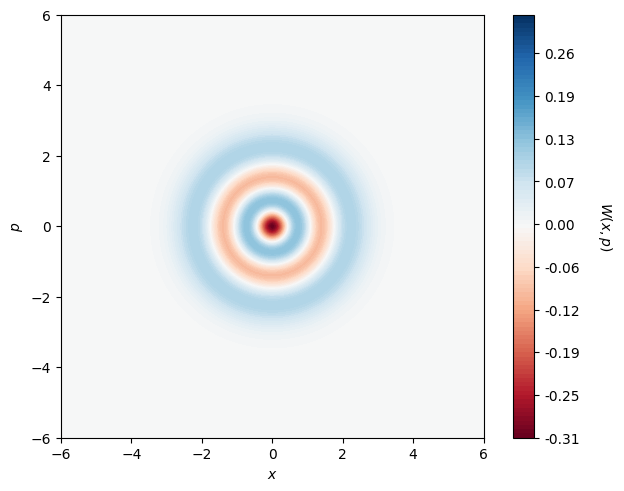

In [7]:
import c2qa
state,_,_ = c2qa.wigner.simulate(circuit)
plot = c2qa.wigner.plot_wigner(circuit, state)

In [8]:
state

Statevector([ 0.        +0.j        ,  0.        +0.j        ,
              0.        +0.j        ,  0.89378126+0.44850313j,
              0.        +0.j        ,  0.        +0.j        ,
              0.        +0.j        , -0.        +0.j        ,
              0.        +0.j        , -0.        +0.j        ,
              0.        +0.j        ,  0.        +0.j        ,
             -0.        +0.j        ,  0.        +0.j        ,
              0.        +0.j        , -0.        +0.j        ],
            dims=(2, 2, 2, 2))


$$
\frac{du}{dt} = - (L+iH)u(t), u(0) = u_0
$$
where $L = \sigma_Z$ and $H = \sigma_X$.


In [ ]:
t = 0.5
k = 0.5

anc_qubits = QumodeRegister(num_qumodes=1, num_qubits_per_qumode=3, name="anc")
sys_qubits = QuantumRegister(1, name="sys")

circ = CVCircuit(anc_qubits, sys_qubits)

circ.cv_initialize(0, anc_qubits)
circ.cv_d(-0.5 * t * k, anc_qubits) # L = Z
circ.cv_c_d(t, anc_qubits[0], sys_qubits[0])

circ.rx(2 * k * t, sys_qubits) # H = \omega X

cr = ClassicalRegister(4, name="meas")
circuit.add_register(cr)
circuit.cv_measure([anc_qubits[0], sys_qubits[0]], cr[:4])

CircuitError: "Bit 'Qubit(QuantumRegister(3, 'anc'), 0)' is not in the circuit."